# 1. Characterization of Data

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns #visualisation
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, classification_report
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.neural_network import MLPClassifier

In [2]:
df= pd.read_csv('NPHA-doctor-visits.csv')

In [3]:
df.head(5)

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
0,3,2,4,3,3,3,0,0,0,0,1,2,3,1,2
1,2,2,4,2,3,3,1,0,0,1,0,3,3,1,1
2,3,2,3,2,3,3,0,0,0,0,1,3,3,4,1
3,1,2,3,2,3,3,0,0,0,1,0,3,3,4,2
4,3,2,3,3,3,3,1,0,0,0,0,2,3,1,2


In [4]:
df.tail(5)

,Number of Doctors Visited,Age,Phyiscal Health,Mental Health,Dental Health,Employment,Stress Keeps Patient from Sleeping,Medication Keeps Patient from Sleeping,Pain Keeps Patient from Sleeping,Bathroom Needs Keeps Patient from Sleeping,Uknown Keeps Patient from Sleeping,Trouble Sleeping,Prescription Sleep Medication,Race,Gender
709,2,2,2,2,2,3,0,0,0,1,0,3,3,1,1
710,3,2,2,2,2,2,1,0,0,0,1,2,3,1,2
711,3,2,4,2,3,3,0,0,0,0,0,3,3,1,1
712,3,2,3,1,3,3,1,0,1,1,1,3,3,1,2
713,2,2,3,2,2,1,1,0,1,1,0,2,3,1,1


In [5]:
df.info() 

<class 'pandas.DataFrame'>
RangeIndex: 714 entries, 0 to 713
Data columns (total 15 columns):
 #   Column                                      Non-Null Count  Dtype
---  ------                                      --------------  -----
 0   Number of Doctors Visited                   714 non-null    int64
 1   Age                                         714 non-null    int64
 2   Phyiscal Health                             714 non-null    int64
 3   Mental Health                               714 non-null    int64
 4   Dental Health                               714 non-null    int64
 5   Employment                                  714 non-null    int64
 6   Stress Keeps Patient from Sleeping          714 non-null    int64
 7   Medication Keeps Patient from Sleeping      714 non-null    int64
 8   Pain Keeps Patient from Sleeping            714 non-null    int64
 9   Bathroom Needs Keeps Patient from Sleeping  714 non-null    int64
 10  Uknown Keeps Patient from Sleeping          714 n

In [6]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Number of Doctors Visited,714.0,2.112045,0.683441,1.0,2.0,2.0,3.0,3.0
Age,714.0,2.000000,0.000000,2.0,2.0,2.0,2.0,2.0
Phyiscal Health,714.0,2.794118,0.900939,-1.0,2.0,3.0,3.0,5.0
Mental Health,714.0,1.988796,0.939928,-1.0,1.0,2.0,3.0,5.0
Dental Health,714.0,3.009804,1.361117,-1.0,2.0,3.0,4.0,6.0
Employment,714.0,2.806723,0.586582,1.0,3.0,3.0,3.0,4.0
Stress Keeps Patient from Sleeping,714.0,0.247899,0.432096,0.0,0.0,0.0,0.0,1.0
Medication Keeps Patient from Sleeping,714.0,0.056022,0.230126,0.0,0.0,0.0,0.0,1.0
Pain Keeps Patient from Sleeping,714.0,0.218487,0.413510,0.0,0.0,0.0,0.0,1.0
Bathroom Needs Keeps Patient from Sleeping,714.0,0.504202,0.500333,0.0,0.0,1.0,1.0,1.0


# 2. Data Pre-processing

In [7]:
df.isnull().sum()

Number of Doctors Visited                     0
Age                                           0
Phyiscal Health                               0
Mental Health                                 0
Dental Health                                 0
Employment                                    0
Stress Keeps Patient from Sleeping            0
Medication Keeps Patient from Sleeping        0
Pain Keeps Patient from Sleeping              0
Bathroom Needs Keeps Patient from Sleeping    0
Uknown Keeps Patient from Sleeping            0
Trouble Sleeping                              0
Prescription Sleep Medication                 0
Race                                          0
Gender                                        0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(42)

In [9]:
df = df.drop_duplicates()
print(df.duplicated().sum()) 
print(df.shape)             

0
(672, 15)


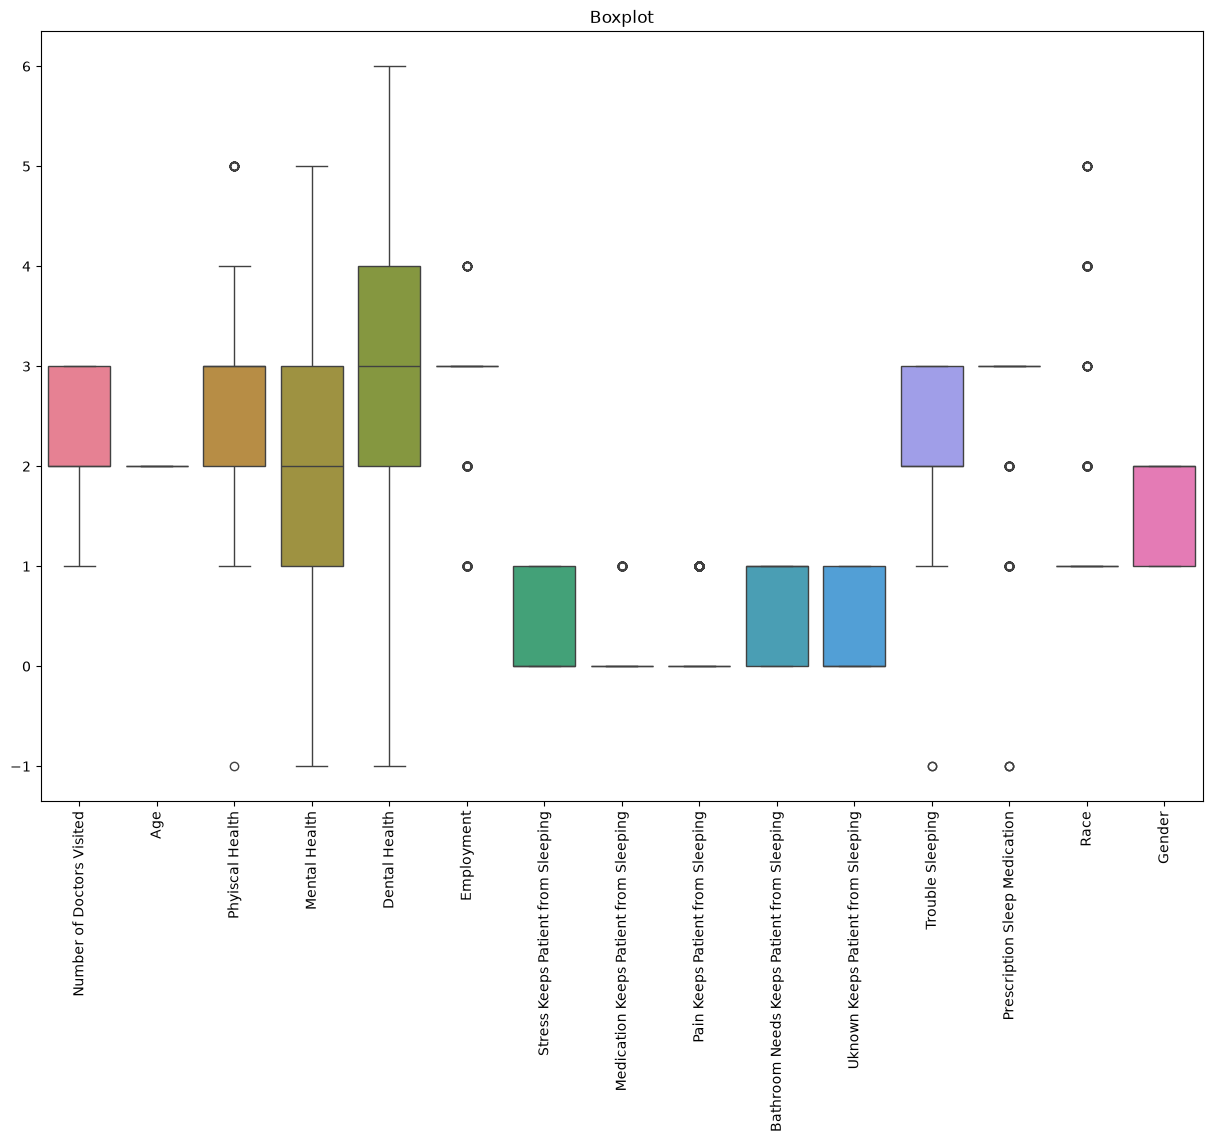

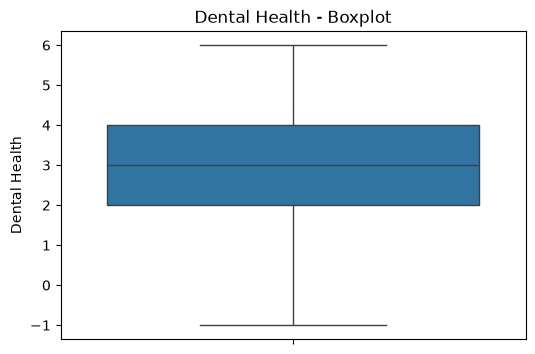

In [10]:
# 1 Outliers detection
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(15, 10))
sns.boxplot(data=df)
plt.xticks(rotation=90) 
plt.title("Boxplot")
plt.show()
plt.figure(figsize=(6, 4))
sns.boxplot(y=df['Dental Health'])
plt.title("Dental Health - Boxplot")
plt.show()

In [11]:
df_cleaned = df.copy()

# check outliers columns
cols_to_check = ['Age', 'Physical Health', 'Mental Health', 'Dental Health']

# remove each column outlier
for col in cols_to_check:
    if col in df_cleaned.columns:
        Q1 = df_cleaned[col].quantile(0.25)
        Q3 = df_cleaned[col].quantile(0.75)
        IQR = Q3 - Q1
        
        lower_bound = Q1 - 3 * IQR
        upper_bound = Q3 + 3 * IQR
        df_cleaned = df_cleaned[(df_cleaned[col] >= lower_bound) & (df_cleaned[col] <= upper_bound)]
print("Rows before removal:", df.shape[0])
print("Rows after removal:", df_cleaned.shape[0])

Rows before removal: 672
Rows after removal: 672


In [12]:
from sklearn.preprocessing import LabelEncoder
import pandas as pd

# (Gender)Label Encoding
le = LabelEncoder()
df_cleaned['Gender'] = le.fit_transform(df_cleaned['Gender'])

# (Race)One-Hot Encoding 
df_cleaned = pd.get_dummies(df_cleaned, columns=['Race'], drop_first=True)

print("After Encoding :")
print(df_cleaned.columns.tolist())

After Encoding :
['Number of Doctors Visited', 'Age', 'Phyiscal Health', 'Mental Health', 'Dental Health', 'Employment', 'Stress Keeps Patient from Sleeping', 'Medication Keeps Patient from Sleeping', 'Pain Keeps Patient from Sleeping', 'Bathroom Needs Keeps Patient from Sleeping', 'Uknown Keeps Patient from Sleeping', 'Trouble Sleeping', 'Prescription Sleep Medication', 'Gender', 'Race_2', 'Race_3', 'Race_4', 'Race_5']


In [13]:
from sklearn.model_selection import train_test_split

# 'Trouble Sleeping'- X 
X = df_cleaned.drop('Trouble Sleeping', axis=1)

# 'Trouble Sleeping' -y 
y = df_cleaned['Trouble Sleeping']

print("X:", X.shape)
print("y:", y.shape)

X: (672, 17)
y: (672,)


In [14]:
# 95:5
X_train_95, X_test_5, y_train_95, y_test_5 = train_test_split(X, y, test_size=0.20, random_state=42)

print("95:5")
print(f"Train size: {X_train_95.shape[0]}")
print(f"Test size:  {X_test_5.shape[0]}")

95:5
Train size: 537
Test size:  135


In [15]:
# 85:15 
# test_size=0.15 нь 15% test, 85% (train) 
X_train_85, X_test_15, y_train_85, y_test_15 = train_test_split(X, y, test_size=0.15, random_state=42)

print("85:15")
print(f"Train size: {X_train_85.shape[0]}")
print(f"Test size:  {X_test_15.shape[0]}")

85:15
Train size: 571
Test size:  101


In [16]:
# 3. 75:25 
# test_size=0.30 нь 30% тест, 70% сургалт (train) болно
X_train_75, X_test_25, y_train_75, y_test_25 = train_test_split(X, y, test_size=0.25, random_state=42)

print("75:25")
print(f"Train size: {X_train_75.shape[0]}")
print(f"Test size:  {X_test_25.shape[0]}")

75:25
Train size: 504
Test size:  168


In [17]:
# Define classifiers for ML models
classifiers = {
    "k-Nearest Neighbors": KNeighborsClassifier(n_neighbors=5),
    "Random Forest": RandomForestClassifier(n_estimators=100, random_state=42, class_weight='balanced'),
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "Support Vector Machine": SVC(kernel='linear', random_state=42, class_weight='balanced')
}

In [18]:
from sklearn.metrics import accuracy_score, classification_report
# 95:5
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 5 % training data
    classifier.fit(X_train_95, y_train_95)
    
    # 2. Predict on the 5% test set
    y_pred = classifier.predict(X_test_5)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_5, y_pred)
    report = classification_report(y_test_5, y_pred, output_dict=True, zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.518519   0.490219 0.518519  0.496386
         Random Forest  0.481481   0.480913 0.481481  0.480656
   Logistic Regression  0.540741   0.556774 0.540741  0.539682
Support Vector Machine  0.555556   0.562458 0.555556  0.552032


In [19]:
from sklearn.metrics import accuracy_score, classification_report
# 85:15
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 70% training data
    classifier.fit(X_train_85, y_train_85)
    
    # 2. Predict on the 20% test set
    y_pred = classifier.predict(X_test_15)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_15, y_pred)
    report = classification_report(y_test_15, y_pred, output_dict=True,zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.485149   0.414401 0.485149  0.446902
         Random Forest  0.425743   0.426160 0.425743  0.418658
   Logistic Regression  0.514851   0.522871 0.514851  0.508937
Support Vector Machine  0.504950   0.483689 0.504950  0.486473


In [20]:
from sklearn.metrics import accuracy_score, classification_report
# 75:25
# Train and evaluate ML model classifiers for 'Trouble Sleeping'
results = []

for name, classifier in classifiers.items():
    # 1. Train the classifier using the 75% training data
    classifier.fit(X_train_75, y_train_75)
    
    # 2. Predict on the 25 test set
    y_pred = classifier.predict(X_test_25)
    
    # 3. Calculate performance metrics
    accuracy = accuracy_score(y_test_25, y_pred)
    report = classification_report(y_test_25, y_pred, output_dict=True,zero_division=0)
    
    precision = report['weighted avg']['precision']
    recall = report['weighted avg']['recall']
    f1_score = report['weighted avg']['f1-score']
    
    # 4. Append results to the list
    results.append([name, accuracy, precision, recall, f1_score])

# Display the results nicely (optional, but recommended)
import pandas as pd
df_results = pd.DataFrame(results, columns=['Model', 'Accuracy', 'Precision', 'Recall', 'F1-Score'])
print(df_results.to_string(index=False))

                 Model  Accuracy  Precision   Recall  F1-Score
   k-Nearest Neighbors  0.511905   0.487306 0.511905  0.493297
         Random Forest  0.476190   0.474554 0.476190  0.475103
   Logistic Regression  0.511905   0.532362 0.511905  0.515927
Support Vector Machine  0.523810   0.552962 0.523810  0.529377


In [21]:
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

# SVC 
svm_model = SVC(random_state=42)

param_grid = {
    'C': [0.1, 1, 10, 100],
    'kernel': ['linear', 'rbf'],
    'gamma': ['scale', 'auto']}

# GridSearchCV 
grid_search_svm = GridSearchCV(
    estimator=svm_model, 
    param_grid=param_grid, 
    cv=5, 
    scoring='accuracy', 
    n_jobs=-1, 
    verbose=1)

print("GridSearchCV")

GridSearchCV


In [22]:
from sklearn.metrics import accuracy_score

# GridSearchCV-г 75:25 
print("GridSearchCV (SVM)")
grid_search_svm.fit(X_train_75, y_train_75)

# Cross-Validation
print("\n best")
print("Best Parameters:", grid_search_svm.best_params_)
print("Best Cross-Validation Accuracy:", round(grid_search_svm.best_score_, 4))

# 25% Test 
best_svm = grid_search_svm.best_estimator_
y_pred_tuned_svm = best_svm.predict(X_test_25)

#  Accuracy
final_accuracy_svm = accuracy_score(y_test_25, y_pred_tuned_svm)
print("\n best")
print(f" before Accuracy (SVM): 57.74%")
print(f" after Accuracy (SVM): {round(final_accuracy_svm * 100, 2)}%")

GridSearchCV (SVM)
Fitting 5 folds for each of 16 candidates, totalling 80 fits


/opt/anaconda3/lib/python3.14/site-packages/sklearn/model_selection/_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(



 best
Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best Cross-Validation Accuracy: 0.5636

 best
 before Accuracy (SVM): 57.74%
 after Accuracy (SVM): 54.76%


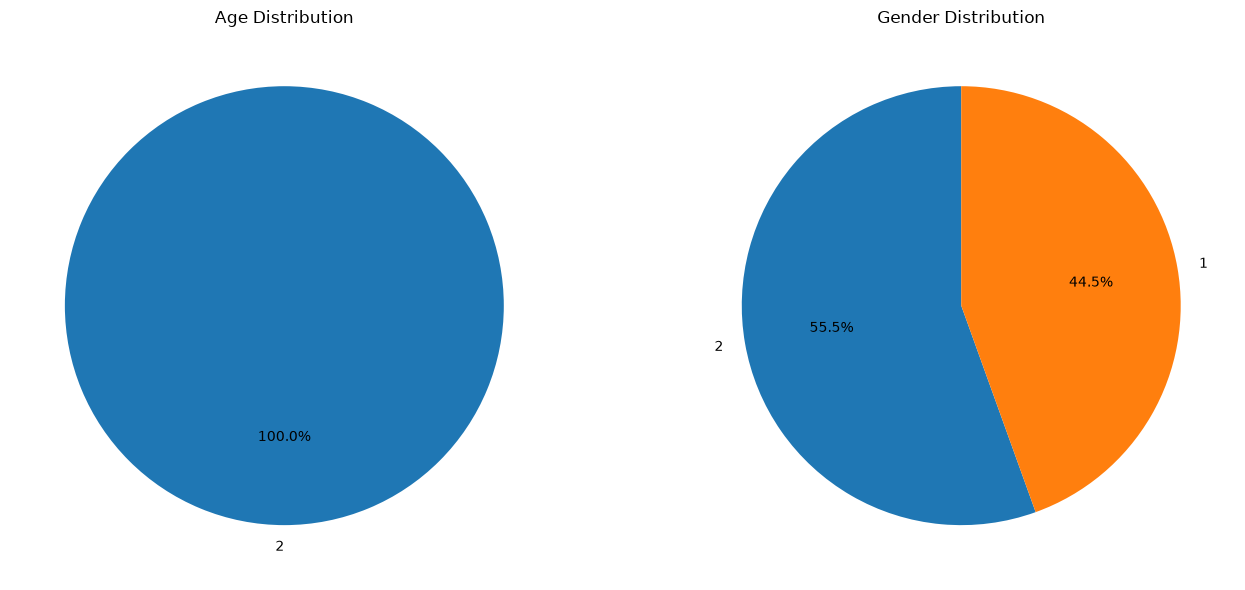

In [23]:
import matplotlib.pyplot as plt

age_counts = df['Age'].value_counts()
gender_counts = df['Gender'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

axes[0].pie(age_counts, labels=age_counts.index, autopct='%1.1f%%', startangle=90)
axes[0].set_title('Age Distribution')

axes[1].pie(gender_counts, labels=gender_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Gender Distribution')

plt.tight_layout()
plt.show()

References

https://archive.ics.uci.edu/dataset/936/national+poll+on+healthy+aging+(npha)